# Notebook 6: Forecasting Project, Part 2: LSTM / GRU
**Phase 3, Day 6**

We load the data (`prepared_data.npz`) and baseline scores (`baseline_scores.csv`) from Day 5, build LSTM and GRU forecasters, compare them with the baselines, plot the predictions over time, try a multi-step forecast and write an honest discussion.

> The files from notebook 5 must be in the same folder (upload them to Colab or work in the same session).

In [1]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

np.random.seed(42)
torch.manual_seed(42)

## Part 1: Loading the data

In [2]:
d = np.load("prepared_data.npz", allow_pickle=True)
K = int(d["K"]); mean = float(d["mean"]); std = float(d["std"])
baseline_table = pd.read_csv("baseline_scores.csv", index_col=0)

to_t = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr, Xva, Xte = [to_t(d[k]).unsqueeze(-1) for k in ("X_train", "X_val", "X_test")]   # (N, K, 1)
ytr, yva, yte = [to_t(d[k]).unsqueeze(-1) for k in ("y_train", "y_val", "y_test")]   # (N, 1)
d_val, d_test = d["d_val"], d["d_test"]

unscale = lambda a: a * std + mean
mae  = lambda a, b: np.mean(np.abs(a - b))
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
real_val, real_test = unscale(yva.squeeze(-1).numpy()), unscale(yte.squeeze(-1).numpy())

print("Window size K =", K, "| train/val/test:", len(Xtr), len(Xva), len(Xte))
print("\nBaselines (from Day 5):")
baseline_table

Window size K = 12 | train/val/test: 88 21 23

Baselines (from Day 5):


,Val MAE,Val RMSE,Test MAE,Test RMSE
Model,,,,
Naive,38.000,45.561,45.130,52.678
Moving avg (3),55.889,66.988,63.957,76.450
Linear (last K),19.325,24.709,12.425,16.139
Seasonal naive (12),24.952,31.039,48.783,50.891


## Part 2: Model and training (with early stopping)
Early stopping: stop training when the validation loss has not improved for `patience` epochs, and restore the weights of the best epoch.

In [3]:
class Forecaster(nn.Module):
    def __init__(self, kind, hidden=32, layers=1, dropout=0.0):
        super().__init__()
        cell = {"LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        self.rnn = cell(1, hidden, num_layers=layers, batch_first=True,
                        dropout=dropout if layers > 1 else 0.0)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def train_model(kind, hidden, layers, dropout, seed=0,
                max_epochs=200, patience=15, bs=16, lr=1e-3):
    torch.manual_seed(seed)
    m = Forecaster(kind, hidden, layers, dropout)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    lf = nn.MSELoss()
    best, best_state, wait, hist = float("inf"), None, 0, []
    for ep in range(max_epochs):
        m.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            lf(m(Xtr[idx]), ytr[idx]).backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            opt.step()
        m.eval()
        with torch.no_grad():
            v = lf(m(Xva), yva).item()
        hist.append(v)
        if v < best - 1e-6:
            best, best_state, wait = v, copy.deepcopy(m.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    m.load_state_dict(best_state)
    m.eval()
    return m, hist, ep + 1

def predict(m, X):
    m.eval()
    with torch.no_grad():
        return m(X).squeeze(-1).numpy()

## Part 3: Trying different configurations
1 and 2 layers, hidden size 32 and 64, dropout (only with 2 layers). Choose using the **validation** score. Do not touch the test set yet.

In [4]:
configs = [(1, 32, 0.0), (1, 64, 0.0), (2, 32, 0.2), (2, 64, 0.2)]
models, rows = {}, []
for kind in ("LSTM", "GRU"):
    for layers, hidden, drop in configs:
        m, hist, epochs = train_model(kind, hidden, layers, drop)
        pv = unscale(predict(m, Xva))
        key = (kind, layers, hidden, drop)
        models[key] = (m, hist)
        rows.append({"kind": kind, "layers": layers, "hidden": hidden, "dropout": drop,
                     "epochs": epochs, "val_MAE": mae(real_val, pv), "val_RMSE": rmse(real_val, pv)})
        print(f"{kind} L{layers} H{hidden} drop{drop}: stopped at epoch {epochs}, val MAE={rows[-1]['val_MAE']:.3f}")

val_results = pd.DataFrame(rows)
val_results.round(3)

LSTM L1 H32 drop0.0: stopped at epoch 23, val MAE=47.716
LSTM L1 H64 drop0.0: stopped at epoch 21, val MAE=46.112
LSTM L2 H32 drop0.2: stopped at epoch 23, val MAE=48.707
LSTM L2 H64 drop0.2: stopped at epoch 19, val MAE=50.477
GRU L1 H32 drop0.0: stopped at epoch 200, val MAE=18.050
GRU L1 H64 drop0.0: stopped at epoch 134, val MAE=21.540
GRU L2 H32 drop0.2: stopped at epoch 22, val MAE=48.877
GRU L2 H64 drop0.2: stopped at epoch 107, val MAE=21.956


,kind,layers,hidden,dropout,epochs,val_MAE,val_RMSE
0,LSTM,1,32,0.0,23,47.716000,66.836998
1,LSTM,1,64,0.0,21,46.112000,63.563000
2,LSTM,2,32,0.2,23,48.707001,68.146004
3,LSTM,2,64,0.2,19,50.477001,61.063000
4,GRU,1,32,0.0,200,18.049999,22.584000
5,GRU,1,64,0.0,134,21.540001,26.264999
6,GRU,2,32,0.2,22,48.876999,65.379997
7,GRU,2,64,0.2,107,21.955999,26.948999


Best configuration of each kind (on validation):
kind  layers  hidden  dropout  epochs   val_MAE  val_RMSE
 GRU       1      32      0.0     200 18.049999    22.584
LSTM       1      64      0.0      21 46.112000    63.563


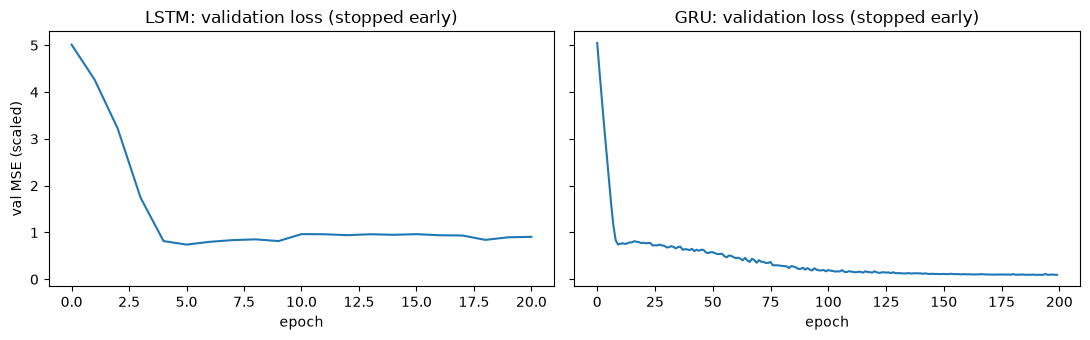

In [5]:
best_rows = val_results.loc[val_results.groupby("kind")["val_MAE"].idxmin()]
best_keys = {r.kind: (r.kind, int(r.layers), int(r.hidden), float(r.dropout)) for r in best_rows.itertuples()}
print("Best configuration of each kind (on validation):")
print(best_rows.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, kind in zip(ax, ("LSTM", "GRU")):
    m, hist = models[best_keys[kind]]
    a.plot(hist); a.set_title(f"{kind}: validation loss (stopped early)")
    a.set_xlabel("epoch")
ax[0].set_ylabel("val MSE (scaled)")
plt.tight_layout(); plt.show()

## Part 4: Evaluating on the test set **only once**
Only the two chosen models (best LSTM, best GRU) are run on the test set. Then we put them in one table with the baselines.

In [6]:
final_rows, test_preds = [], {}
for kind in ("LSTM", "GRU"):
    key = best_keys[kind]
    m, _ = models[key]
    pv, pt = unscale(predict(m, Xva)), unscale(predict(m, Xte))
    test_preds[kind] = pt
    name = f"{kind} (L{key[1]}, H{key[2]})"
    final_rows.append({"Model": name,
                       "Val MAE": mae(real_val, pv), "Val RMSE": rmse(real_val, pv),
                       "Test MAE": mae(real_test, pt), "Test RMSE": rmse(real_test, pt)})

results = pd.concat([baseline_table, pd.DataFrame(final_rows).set_index("Model")]).round(3)
results.to_csv("results_table.csv")
results

,Val MAE,Val RMSE,Test MAE,Test RMSE
Model,,,,
Naive,38.000,45.561,45.130,52.678
Moving avg (3),55.889,66.988,63.957,76.450
Linear (last K),19.325,24.709,12.425,16.139
Seasonal naive (12),24.952,31.039,48.783,50.891
"LSTM (L1, H64)",46.112,63.563,91.051,114.542
"GRU (L1, H32)",18.050,22.584,51.939,64.274


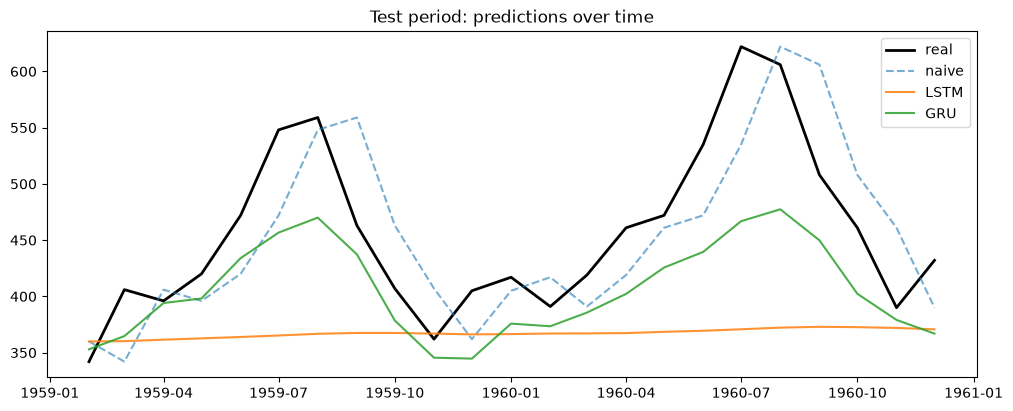

In [7]:
naive_test = unscale(Xte[:, -1, 0].numpy())

plt.figure(figsize=(12, 4.5))
plt.plot(d_test, real_test, label="real", color="black", lw=2)
plt.plot(d_test, naive_test, label="naive", alpha=0.6, ls="--")
for kind, p in test_preds.items():
    plt.plot(d_test, p, label=kind, alpha=0.85)
plt.legend(); plt.title("Test period: predictions over time")
plt.savefig("test_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

## Part 5: An honest analysis
Does the model really beat the naive baseline, or is the difference just noise?

In [8]:
best_kind = min(best_keys, key=lambda k: val_results[(val_results.kind == k)]["val_MAE"].min())
best_model = models[best_keys[best_kind]][0]
p = test_preds[best_kind]
naive_mae, model_mae = mae(real_test, naive_test), mae(real_test, p)
gain = (naive_mae - model_mae) / naive_mae * 100
print(f"Best model: {best_kind}")
print(f"Test MAE: naive={naive_mae:.3f}  model={model_mae:.3f}  ->  {gain:+.1f}% (positive = model is better)")

# (1) Paired comparison: |naive error| - |model error| at every test point
diff = np.abs(real_test - naive_test) - np.abs(real_test - p)
se = diff.std(ddof=1) / np.sqrt(len(diff))
print(f"\nAverage difference (naive - model) = {diff.mean():.3f}  (+/- {1.96*se:.3f}, ~95% range)")
print("Is the difference larger than the noise?", "Yes" if abs(diff.mean()) > 1.96 * se else "No, the difference is within the noise")

# (2) Lag check: is the model just copying the real series one step late?
lag_mae  = mae(real_test[:-1], p[1:])    # compare pred[t+1] with real[t]
same_mae = mae(real_test, p)
print(f"\nModel vs real (same time): {same_mae:.3f} | model vs real (shifted by 1 step): {lag_mae:.3f}")
print("Is the model lagging like the naive baseline?", "Probably yes" if lag_mae < same_mae else "Does not look like it")

Best model: GRU
Test MAE: naive=45.130  model=51.939  ->  -15.1% (positive = model is better)

Average difference (naive - model) = -6.808  (+/- 17.344, ~95% range)
Is the difference larger than the noise? No, the difference is within the noise

Model vs real (same time): 51.939 | model vs real (shifted by 1 step): 53.243
Is the model lagging like the naive baseline? Does not look like it


In [9]:
# (3) Effect of the seed: same config, 5 different seeds, validation MAE
naive_val = baseline_table.loc["Naive", "Val MAE"]
for kind in ("LSTM", "GRU"):
    _, L, H, drop = best_keys[kind]
    scores = []
    for seed in range(5):
        m, _, _ = train_model(kind, H, L, drop, seed=seed)
        scores.append(mae(real_val, unscale(predict(m, Xva))))
    print(f"{kind}: val MAE = {np.mean(scores):.3f} +/- {np.std(scores):.3f} (5 seeds) | naive val MAE = {naive_val:.3f}")

LSTM: val MAE = 46.383 +/- 0.457 (5 seeds) | naive val MAE = 38.000
GRU: val MAE = 29.708 +/- 13.205 (5 seeds) | naive val MAE = 38.000


## Part 6: Multi-step forecast
We predict the next `HORIZON` steps. The model feeds its own prediction back in as the input for the next step (**recursive** forecasting). Watch how fast the error grows.

Horizon:    [1, 2, 3, 4, 5, 6]
Model MAE:  [48.508 70.35  72.676 73.389 71.159 69.444]
Naive MAE:  [ 42.444  68.556  82.889  98.611 107.5   107.167]


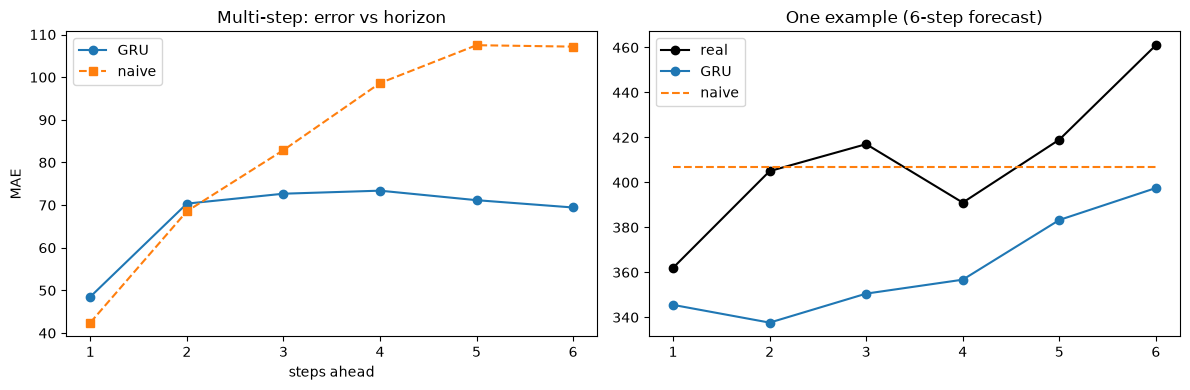

In [10]:
HORIZON = 6
N = len(Xte)
M = N - HORIZON + 1
idx = np.arange(M)[:, None] + np.arange(HORIZON)[None, :]
real_ms = real_test[idx]                                  # (M, HORIZON)

w = Xte[:M].clone()                                       # (M, K, 1)
steps = []
with torch.no_grad():
    for h in range(HORIZON):
        p_h = best_model(w)                               # (M, 1)
        steps.append(p_h.squeeze(-1).numpy())
        w = torch.cat([w[:, 1:, :], p_h.unsqueeze(-1)], dim=1)   # slide the window
pred_ms = unscale(np.stack(steps, axis=1))                # (M, HORIZON)
naive_ms = np.repeat(unscale(Xte[:M, -1, 0].numpy())[:, None], HORIZON, axis=1)

err_model = np.abs(pred_ms - real_ms).mean(axis=0)
err_naive = np.abs(naive_ms - real_ms).mean(axis=0)
print("Horizon:   ", list(range(1, HORIZON + 1)))
print("Model MAE: ", np.round(err_model, 3))
print("Naive MAE: ", np.round(err_naive, 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, HORIZON + 1), err_model, "o-", label=best_kind)
ax[0].plot(range(1, HORIZON + 1), err_naive, "s--", label="naive")
ax[0].set_xlabel("steps ahead"); ax[0].set_ylabel("MAE"); ax[0].legend()
ax[0].set_title("Multi-step: error vs horizon")

i0 = M // 2
ax[1].plot(range(1, HORIZON + 1), real_ms[i0], "k-o", label="real")
ax[1].plot(range(1, HORIZON + 1), pred_ms[i0], "-o", label=best_kind)
ax[1].plot(range(1, HORIZON + 1), naive_ms[i0], "--", label="naive")
ax[1].set_title(f"One example ({HORIZON}-step forecast)"); ax[1].legend()
plt.tight_layout()
plt.savefig("multi_step.png", dpi=150, bbox_inches="tight")
plt.show()

## Discussion (write in your own words, using your actual numbers)
1. **Did the model beat the naive baseline? By what percentage?** (see `gain` in Part 5)
2. **Is the difference larger than the noise?** (see the paired comparison and the seed variation)
3. **What does the plot show?** Are the predictions just following the real series one step late? What happens at peaks or turning points?
4. **Multi-step:** how does the error grow with the horizon? How does it compare with naive?
5. **Effect of the dataset:** how do the results differ between seasonal data (airline) and stock data, and why?
6. **Limitations:** a small test set, a single split, a limited hyperparameter search.

> If the model cannot beat the naive baseline, that is a valid and honest result. On stock prices this is common.